In [1]:
!pip install datasets

In [2]:
import os
import pandas as pd
from datasets import load_dataset

imdb = load_dataset("stanfordnlp/imdb")

In [3]:
print(imdb)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


In [4]:
print(os.path.exists("Sentimentscope"))

True


In [5]:
project_dir = os.path.join(os.getcwd(), "Sentimentscope")
os.makedirs(project_dir, exist_ok=True)

print("Project folder created!")
print(project_dir)

Project folder created!
C:\Users\Welcome\OneDrive\Documents\Sentimentanalysisaws\Sentimentscope


In [6]:
print(os.path.exists("Sentimentscope"))

True


In [7]:
import os

project_dir = os.getcwd()

folders = [
    "aclImdb/train/pos",
    "aclImdb/train/neg",
    "aclImdb/train/unsup",
    "aclImdb/test/pos",
    "aclImdb/test/neg"
]

for folder in folders:
    os.makedirs(os.path.join(project_dir, folder), exist_ok=True)

print("Dataset folders created successfully!")

Dataset folders created successfully!


In [8]:
for folder in folders:
    path = os.path.join(project_dir, folder)
    print(folder, os.path.exists(path))

aclImdb/train/pos True
aclImdb/train/neg True
aclImdb/train/unsup True
aclImdb/test/pos True
aclImdb/test/neg True


In [9]:
print(imdb)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


In [10]:
for i, review in enumerate(imdb["train"]):
    folder = "pos" if review["label"] == 1 else "neg"

    file_path = os.path.join(
        project_dir, "aclImdb", "train", folder, f"{i}.txt"
    )

    with open(file_path, "w", encoding="utf-8") as f:
        f.write(review["text"])

print("Training reviews saved successfully!")

Training reviews saved successfully!


In [11]:
def load_dataset(folder):
    reviews = []

    for filename in os.listdir(folder):
        file_path = os.path.join(folder, filename)

        with open(file_path, 'r', encoding='utf-8') as f:
            reviews.append(f.read())

    return reviews

In [12]:
project_dir = os.getcwd()

train_pos_path = os.path.join(project_dir, "aclImdb", "train", "pos")
train_neg_path = os.path.join(project_dir, "aclImdb", "train", "neg")

test_pos_path = os.path.join(project_dir, "aclImdb", "test", "pos")
test_neg_path = os.path.join(project_dir, "aclImdb", "test", "neg")

In [13]:
print(os.path.exists(train_pos_path))
print(os.path.exists(train_neg_path))
print(os.path.exists(test_pos_path))
print(os.path.exists(test_neg_path))

True
True
True
True


In [14]:
train_pos = load_dataset(train_pos_path)
train_neg = load_dataset(train_neg_path)

test_pos = load_dataset(test_pos_path)
test_neg = load_dataset(test_neg_path)

In [15]:
for i, review in enumerate(imdb["test"]):
    folder = "pos" if review["label"] == 1 else "neg"

    file_path = os.path.join(
        project_dir, "aclImdb", "test", folder, f"{i}.txt"
    )

    with open(file_path, "w", encoding="utf-8") as f:
        f.write(review["text"])

    if (i + 1) % 5000 == 0:
        print(f"Saved {i + 1} test reviews")

print("All test reviews saved!")

Saved 5000 test reviews
Saved 10000 test reviews
Saved 15000 test reviews
Saved 20000 test reviews
Saved 25000 test reviews
All test reviews saved!


In [16]:
train_df = pd.DataFrame({
    'review': train_pos + train_neg,
    'label': [1] * len(train_pos) + [0] * len(train_neg)
})

test_df = pd.DataFrame({
    'review': test_pos + test_neg,
    'label': [1] * len(test_pos) + [0] * len(test_neg)
})

print(train_df.head())

                                              review  label
0  Zentropa has much in common with The Third Man...      1
1  Zentropa is the most original movie I've seen ...      1
2  Lars Von Trier is never backward in trying out...      1
3  *Contains spoilers due to me having to describ...      1
4  That was the first thing that sprang to mind a...      1


In [17]:
print("Train positive:", len(train_pos))
print("Train negative:", len(train_neg))

print("Test positive:", len(test_pos))
print("Test negative:", len(test_neg))

print("Test DataFrame:", test_df.shape)


Train positive: 12500
Train negative: 12500
Test positive: 12500
Test negative: 12500
Test DataFrame: (25000, 2)


In [18]:
# Assert that both datasets have the expected number of rows
assert train_df.shape[0] == 25000, "Training dataset does not have 25000 rows."
assert test_df.shape[0] == 25000, "Testing dataset does not have 25000 rows."

# Assert that both datasets have exactly two columns
assert train_df.shape[1] == 2, "Training dataset does not have exactly 2 columns."
assert test_df.shape[1] == 2, "Testing dataset does not have exactly 2 columns."


In [19]:
#Exploring dataset
print("Training dataset information")
train_df.info()

print("\nTesting dataset information")
test_df.info()

Training dataset information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   review  25000 non-null  object
 1   label   25000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 390.8+ KB

Testing dataset information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   review  25000 non-null  object
 1   label   25000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 390.8+ KB


In [20]:
print(train_df.describe(include='all'))

                                                   review        label
count                                               25000  25000.00000
unique                                              24904          NaN
top     How has this piece of crap stayed on TV this l...          NaN
freq                                                    3          NaN
mean                                                  NaN      0.50000
std                                                   NaN      0.50001
min                                                   NaN      0.00000
25%                                                   NaN      0.00000
50%                                                   NaN      0.50000
75%                                                   NaN      1.00000
max                                                   NaN      1.00000


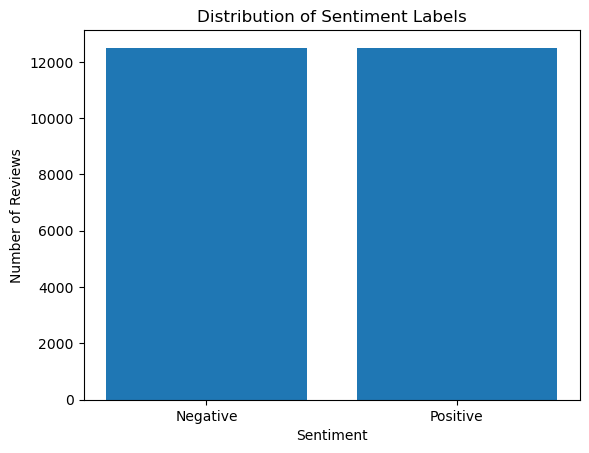

In [21]:
import matplotlib.pyplot as plt

label_counts = train_df['label'].value_counts().sort_index()

plt.bar(['Negative', 'Positive'], label_counts.values)
plt.title('Distribution of Sentiment Labels')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.show()

In [22]:
train_df['review_length'] = train_df['review'].apply(
    lambda x: len(x.split())
)

print(train_df['review_length'].describe())

count    25000.000000
mean       233.787200
std        173.733032
min         10.000000
25%        127.000000
50%        174.000000
75%        284.000000
max       2470.000000
Name: review_length, dtype: float64


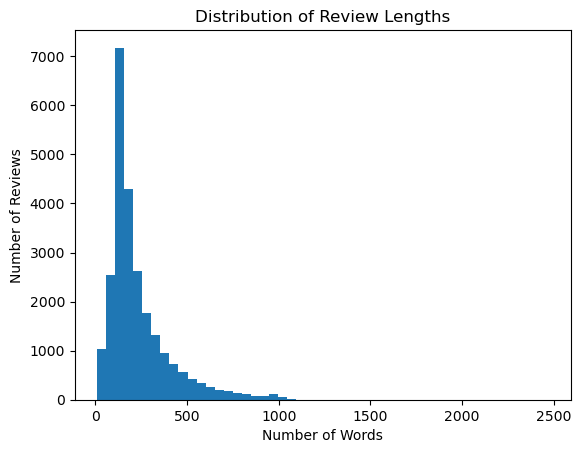

In [23]:
plt.hist(train_df['review_length'], bins=50)
plt.title('Distribution of Review Lengths')
plt.xlabel('Number of Words')
plt.ylabel('Number of Reviews')
plt.show()

In [24]:
print("POSITIVE REVIEWS:\n")

for review in train_df[train_df['label'] == 1]['review'].head(3):
    print(review[:500])
    print("-" * 50)

POSITIVE REVIEWS:

Zentropa has much in common with The Third Man, another noir-like film set among the rubble of postwar Europe. Like TTM, there is much inventive camera work. There is an innocent American who gets emotionally involved with a woman he doesn't really understand, and whose naivety is all the more striking in contrast with the natives.<br /><br />But I'd have to say that The Third Man has a more well-crafted storyline. Zentropa is a bit disjointed in this respect. Perhaps this is intentional: it is 
--------------------------------------------------
Zentropa is the most original movie I've seen in years. If you like unique thrillers that are influenced by film noir, then this is just the right cure for all of those Hollywood summer blockbusters clogging the theaters these days. Von Trier's follow-ups like Breaking the Waves have gotten more acclaim, but this is really his best work. It is flashy without being distracting and offers the perfect combination of suspense and

In [25]:
print("NEGATIVE REVIEWS:\n")

for review in train_df[train_df['label'] == 0]['review'].head(3):
    print(review[:500])
    print("-" * 50)

NEGATIVE REVIEWS:

I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attent
--------------------------------------------------
"I Am Curious: Yellow" is a risible and pretentious steaming pile. It doesn't matter what one's political views are because this film can hardly be taken seriously on any level. As for the claim that frontal male nudity is an automatic NC-17, that isn't true. I've seen R-rated films with male nudity. Granted, they only offer some fleeting views, but where are the R-rated films with gaping vulvas and flapping labia? Nowhere, b

In [26]:
#Prep of dataset
train_size = int(0.9 * len(train_df))

shuffled_df = train_df.sample(frac=1, random_state=42).reset_index(drop=True)
train_data = shuffled_df.iloc[:train_size]
val_data = shuffled_df.iloc[train_size:]

In [27]:
print("Training data:", train_data.shape)
print("Validation data:", val_data.shape)

print("\nTraining label distribution:")
print(train_data['label'].value_counts())

print("\nValidation label distribution:")
print(val_data['label'].value_counts())

Training data: (22500, 3)
Validation data: (2500, 3)

Training label distribution:
label
1    11253
0    11247
Name: count, dtype: int64

Validation label distribution:
label
0    1253
1    1247
Name: count, dtype: int64


In [28]:
%pip install transformers

Note: you may need to restart the kernel to use updated packages.


In [29]:
from transformers import AutoTokenizer

# Initialize tokenizer
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

In [30]:
%pip install torch

Note: you may need to restart the kernel to use updated packages.


In [31]:
# Take sample inputs from the dataset
sample_texts = train_data['review'].sample(3, random_state=42).tolist()

# Tokenize sample inputs
tokenized_samples = tokenizer(sample_texts, truncation=True, padding="max_length", max_length=128, return_tensors="pt")

In [32]:
print(tokenized_samples)

{'input_ids': tensor([[  101,  1045,  3473,  2039,  3666,  8040,  9541,  3762,  1998,  2031,
          2042,  1037,  5470,  5091,  1012,  2023,  9476,  5829,  2185,  2013,
          1996,  2168,  2214,  9410,  2008,  2064,  2131, 11771,  2000,  7193,
          1012,  1996, 19302,  2015,  1999,  7308,  9410,  4152,  2214,  1998,
          2023,  9476,  2003,  1037,  2689,  2013,  2008,  1012,  2009,  1005,
          1055,  2025,  3214,  2000,  5672,  1996,  8040,  9541,  3762,  6080,
          2009,  1005,  1055,  2074,  1037,  3338,  2013,  1996,  2168,  2214,
          4126,  3496,  2005,  2119,  7193,  1998,  4898,  1045,  1005,  1049,
          2469,  1012,  1996,  9476,  1005,  1055,  3579,  2003,  2006,  8040,
          9541,  3762,  1998, 25741,  2040, 22490,  2015,  1037,  2312,  7680,
          1997,  2769,  1998,  2224,  2008,  2769,  2000, 16215, 18367,  2088,
          9187,  3488,  2013,  1037,  5506,  7155,  1998,  2010, 27571,  3619,
          1012,  2235, 14822,  2015,  

In [33]:
#Implement a DataLoader in PyTorch
#custom dataset class
import torch
from torch.utils.data import Dataset
MAX_LENGTH = 128

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


In [39]:
from torch.utils.data import Dataset

class IMDBDataset(Dataset):

    def __init__(self, data, tokenizer, max_length=MAX_LENGTH):
        self.data = data.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        review = self.data.iloc[idx]['review']
        label = self.data.iloc[idx]['label']
        
        encoding = self.tokenizer(
            review,
            truncation=True,
            padding='max_length',
            max_length=self.max_length,
            return_tensors='pt'
        )
        input_ids = encoding['input_ids'].squeeze(0)
        return input_ids, int(label)


In [40]:
# Initialize the datasets
train_dataset = IMDBDataset(train_data, tokenizer)
val_dataset = IMDBDataset(val_data, tokenizer)
test_dataset = IMDBDataset(test_df, tokenizer)

In [41]:
#dataloader
from torch.utils.data import DataLoader

# Define batch size
BATCH_SIZE = 32

# Create DataLoader instances
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

In [42]:
assert len(train_dataset) == 22500, "Train dataset length mismatch!"
assert len(val_dataset) == 2500, "Validation dataset length mismatch!"
assert len(test_dataset) == 25000, "Test dataset length mismatch!"

import numpy as np

# Check the first item in the train dataset
input_ids, label = train_dataset[0]
assert isinstance(input_ids, torch.Tensor), "Input IDs should be a torch.Tensor!"
assert isinstance(label, (int, np.integer)), "Label should be an integer or int-like!"

# Ensure the input IDs tensor has the correct shape
assert input_ids.shape[0] == train_dataset.max_length, "Input IDs tensor has incorrect length!"

In [43]:
#Customize the Transformer Architecture
config = {
    "vocabulary_size": tokenizer.vocab_size,  # e.g., ~30522 for bert-base-uncased
    "num_classes": 2,                         # binary classification (pos/neg)
    "d_embed": 128,
    "context_size": MAX_LENGTH,
    "layers_num": 4,
    "heads_num": 4,
    "head_size": 32,  # 4 heads * 32 = 128 -> matches d_embed
    "dropout_rate": 0.1,
    "use_bias": True
}

In [44]:
import torch.nn as nn
import math

class AttentionHead(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.Q_weights = nn.Linear(config["d_embed"], config["head_size"], bias=config["use_bias"])
        self.K_weights = nn.Linear(config["d_embed"], config["head_size"], bias=config["use_bias"])
        self.V_weights = nn.Linear(config["d_embed"], config["head_size"], bias=config["use_bias"])

        self.dropout = nn.Dropout(config["dropout_rate"])

        casual_attention_mask = torch.tril(torch.ones(config["context_size"], config["context_size"]))
        self.register_buffer('casual_attention_mask', casual_attention_mask)

    def forward(self, input):
        batch_size, tokens_num, d_embed = input.shape
        Q = self.Q_weights(input)  # (B, T, head_size)
        K = self.K_weights(input)  # (B, T, head_size)
        V = self.V_weights(input)  # (B, T, head_size)

        # Q @ K^T => (B, T, T)
        attention_scores = Q @ K.transpose(1, 2)

        # Casual Mask
        attention_scores = attention_scores.masked_fill(
            self.casual_attention_mask[:tokens_num, :tokens_num] == 0,
            float('-inf')
        )
        attention_scores = attention_scores / math.sqrt(K.shape[-1])
        attention_scores = torch.softmax(attention_scores, dim=-1)
        attention_scores = self.dropout(attention_scores)

        return attention_scores @ V

In [45]:
# Instantiate the AttentionHead
attention_head = AttentionHead(config).to(device)

# Create a dummy input of shape (32, 128, 128)
dummy_input = torch.randn(BATCH_SIZE, config["context_size"], config["d_embed"]).to(device)

# Forward pass
attention_output = attention_head(dummy_input)
print("AttentionHead output shape:", attention_output.shape)

AttentionHead output shape: torch.Size([32, 128, 32])


In [46]:
class MultiHeadAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        heads_list = [AttentionHead(config) for _ in range(config["heads_num"])]
        self.heads = nn.ModuleList(heads_list)

        self.linear = nn.Linear(config["heads_num"] * config["head_size"], config["d_embed"])
        self.dropout = nn.Dropout(config["dropout_rate"])

    def forward(self, input):
        heads_outputs = [head(input) for head in self.heads]
        x = torch.cat(heads_outputs, dim=-1)  # (B, T, heads_num * head_size)
        x = self.linear(x)                   # (B, T, d_embed)
        x = self.dropout(x)
        return x

In [47]:
# Instantiate MultiHeadAttention
multi_head_attention = MultiHeadAttention(config).to(device)

# Same dummy input: (32, 128, 128)
dummy_input = torch.randn(BATCH_SIZE, config["context_size"], config["d_embed"]).to(device)

# Forward pass
mha_output = multi_head_attention(dummy_input)
print("MultiHeadAttention output shape:", mha_output.shape)

MultiHeadAttention output shape: torch.Size([32, 128, 128])


In [48]:
class FeedForward(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.linear_layers = nn.Sequential(
            nn.Linear(config["d_embed"], 4 * config["d_embed"]),
            nn.GELU(),
            nn.Linear(4 * config["d_embed"], config["d_embed"]),
            nn.Dropout(config["dropout_rate"])
        )

    def forward(self, input):
        return self.linear_layers(input)

In [49]:
# Instantiate FeedForward
feed_forward = FeedForward(config).to(device)

# Dummy input: (32, 128, 128)
dummy_input = torch.randn(BATCH_SIZE, config["context_size"], config["d_embed"]).to(device)

# Forward pass
ff_output = feed_forward(dummy_input)
print("FeedForward output shape:", ff_output.shape)

FeedForward output shape: torch.Size([32, 128, 128])


In [50]:
class Block(nn.Module):
    def __init__(self, config):
        super().__init__()

        self.multi_head = MultiHeadAttention(config)
        self.layer_norm_1 = nn.LayerNorm(config["d_embed"])

        self.feed_forward = FeedForward(config)
        self.layer_norm_2 = nn.LayerNorm(config["d_embed"])

    def forward(self, input):
        x = input
        x = x + self.multi_head(self.layer_norm_1(x))
        x = x + self.feed_forward(self.layer_norm_2(x))
        return x

In [51]:
# Instantiate a single Block
block = Block(config).to(device)

# Dummy input: (32, 128, 128)
dummy_input = torch.randn(BATCH_SIZE, config["context_size"], config["d_embed"]).to(device)

# Forward pass
block_output = block(dummy_input)
print("Block output shape:", block_output.shape)

Block output shape: torch.Size([32, 128, 128])


In [52]:
class DemoGPT(nn.Module):
    def __init__(self, config):
        
        super().__init__()
        # Token embedding layer: Maps token indices to embedding vectors.
        self.token_embedding_layer = nn.Embedding(config["vocabulary_size"], config["d_embed"])
        
        # Positional embedding layer: Adds positional information to the embeddings.
        self.positional_embedding_layer = nn.Embedding(config["context_size"], config["d_embed"])
        
        # Transformer layers: Stacked sequence of transformer blocks.
        blocks = [Block(config) for _ in range(config["layers_num"])]
        self.layers = nn.Sequential(*blocks)
        
        # Layer normalization: Applied to stabilize training.
        self.layer_norm = nn.LayerNorm(config["d_embed"])
        
        # TODO: Implement classification output layer - Maps pooled embeddings to class logits.
        self.classification_head = nn.Linear(
            config["d_embed"],
            config["num_classes"],
            bias=False
        )

    def forward(self, token_ids):
        batch_size, tokens_num = token_ids.shape

        # Step 1: Create embeddings for tokens and their positions
        x = self.token_embedding_layer(token_ids)  # Shape: (B, T, d_embed)
        positions = torch.arange(tokens_num, device=token_ids.device)  # Shape: (T,)
        pos_embed = self.positional_embedding_layer(positions)  # Shape: (T, d_embed)
        x = x + pos_embed.unsqueeze(0)  # Add positional embeddings to token embeddings
        
        # Step 2: Pass embeddings through transformer layers
        x = self.layers(x)  # Shape: (B, T, d_embed)
        x = self.layer_norm(x)  # Normalize across the feature dimension
        
        # Step 3: TODO: Apply mean pooling across the time dimension  # Shape: (B, d_embed)
        x = torch.mean(x, dim=1)
        
        # Step 4: TODO: Generate logits for classification  # Shape: (B, num_classes)
        logits = self.classification_head(x)
        
        return logits

In [53]:
# Instantiate the model
demo_gpt = DemoGPT(config).to(device)

# Suppose we have a batch of size 32, each with a sequence length of 128
dummy_token_ids = torch.randint(
    0, config["vocabulary_size"], 
    (BATCH_SIZE, config["context_size"])
).to(device)

# Forward pass
logits = demo_gpt(dummy_token_ids)

print("DemoGPT output shape:", logits.shape)
print("Logits sample:\n", logits[:2])  # Print first two examples' logits

DemoGPT output shape: torch.Size([32, 2])
Logits sample:
 tensor([[-0.0762, -0.0494],
        [-0.1331,  0.0401]], grad_fn=<SliceBackward0>)


In [54]:
# Assert that the number of logits matches the number of classes
assert logits.size(1) == config["num_classes"], (
    f"Expected number of classes {config['num_classes']}, "
    f"but got {logits.size(1)}"
)

# Assert that the batch size of the output matches the input batch size
assert logits.size(0) == BATCH_SIZE, (
    f"Expected batch size {BATCH_SIZE}, "
    f"but got {logits.size(0)}"
)

In [62]:
#Implement Accuracy Calculation Method 
def calculate_accuracy(model, data_loader, device):
     model.eval()

     total_correct = 0
     total_samples = 0

     with torch.no_grad():
         for input_ids, labels in data_loader:
             input_ids = input_ids.to(device)
             labels = labels.to(device)

             logits = model(input_ids)
             predictions = torch.argmax(logits, dim=1)

             total_correct += (predictions == labels).sum().item()
             total_samples += labels.size(0)
     accuracy = (total_correct / total_samples) * 100
     return accuracy

In [63]:
model = DemoGPT(config).to(device)

In [64]:
validation_accuracy = calculate_accuracy(model, val_loader, device)
print(f"Validation Accuracy: {validation_accuracy:.2f}%")

Validation Accuracy: 49.20%


In [67]:
import torch.optim as optim

# Define the device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Training parameters
EPOCHS = 5

# Initialize model, loss, and optimizer
model = DemoGPT(config).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=3e-4)

# Training loop
for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0

    for step, (input_ids, labels) in enumerate(train_loader):
        # Move data to device
        input_ids = input_ids.to(device)
        labels = labels.to(device)

        # TODO: Implement forward pass
        logits = model(input_ids)
        
        # TODO: Calculate loss
        loss = criterion(logits, labels)

        # TODO: Set gradients to zero
        optimizer.zero_grad()
        
        # TODO: Backward pass
        loss.backward()
        
        # TODO: Step the optimizer
        optimizer.step()

        running_loss += loss.item()

        # Log training progress
        if (step + 1) % 100 == 0:
            print(f"Epoch [{epoch+1}/{EPOCHS}], Step [{step+1}/{len(train_loader)}], "
                  f"Loss: {running_loss/100:.4f}")
            running_loss = 0.0

    # Evaluate validation accuracy
    val_accuracy = calculate_accuracy(model, val_loader, device)
    print(f"Epoch {epoch+1} - Validation Accuracy: {val_accuracy:.2f}%")

Epoch [1/5], Step [100/704], Loss: 0.6914
Epoch [1/5], Step [200/704], Loss: 0.6725
Epoch [1/5], Step [300/704], Loss: 0.6505
Epoch [1/5], Step [400/704], Loss: 0.6303
Epoch [1/5], Step [500/704], Loss: 0.5889
Epoch [1/5], Step [600/704], Loss: 0.5618
Epoch [1/5], Step [700/704], Loss: 0.5752
Epoch 1 - Validation Accuracy: 67.16%
Epoch [2/5], Step [100/704], Loss: 0.5299
Epoch [2/5], Step [200/704], Loss: 0.4969
Epoch [2/5], Step [300/704], Loss: 0.5027
Epoch [2/5], Step [400/704], Loss: 0.5071
Epoch [2/5], Step [500/704], Loss: 0.5024
Epoch [2/5], Step [600/704], Loss: 0.4737
Epoch [2/5], Step [700/704], Loss: 0.4861
Epoch 2 - Validation Accuracy: 77.52%
Epoch [3/5], Step [100/704], Loss: 0.4481
Epoch [3/5], Step [200/704], Loss: 0.4427
Epoch [3/5], Step [300/704], Loss: 0.4247
Epoch [3/5], Step [400/704], Loss: 0.4244
Epoch [3/5], Step [500/704], Loss: 0.4385
Epoch [3/5], Step [600/704], Loss: 0.4135
Epoch [3/5], Step [700/704], Loss: 0.4153
Epoch 3 - Validation Accuracy: 79.04%
Epoc

In [66]:
test_accuracy = calculate_accuracy(model, test_loader, device)

print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Accuracy: 75.31%


In [68]:
test_accuracy = calculate_accuracy(model, test_loader, device)

print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Accuracy: 77.14%


In [ ]:
#conclusion

In this project, I built a movie review sentiment analysis model using PyTorch and the IMDB dataset.
The dataset contained 50,000 movie reviews, which I divided into three parts:
-22,500 reviews for training
-2,500 reviews for validation
-25,000 reviews for testing
    
I used the BERT tokenizer to convert the reviews into tokens and built a custom transformer model called DemoGPT.
The model learns to classify reviews as either positive or negative.
    
I trained the model for 3 epochs and got a test accuracy of 75.31%, which is slightly above the target of 75%.
I also tried increasing the training epochs from 3 to 5 to see if it could improve the model accuracy.
The test accuracy after epochs 5 is 77.14%

#Key Takeaways

1. Learned how to work with a real-world movie review dataset and prepare it for model training.
2. Understood how text is converted into tokens using the BERT tokenizer.
3. Learned how to create a custom Dataset class in PyTorch.
4. Got a basic understanding of how transformer models work and how embeddings help process text.
5. Learned how a model is trained using forward pass, loss calculation, backpropagation and an optimizer.
6. Understood how to check model performance using validation and test accuracy.
7. Learned how changing training parameters, such as the number of epochs, can affect model performance.
8. Gained experience in finding errors, debugging code and completing an ML project step by step.